In [5]:
pip install pandas


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Users\nidhi\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [6]:
import pandas as pd

In [8]:
#  task 1
import pandas as pd

data = {
    'date': [
        '2026-01-05', '2026-01-12', '2026-02-03',
        '2026-02-15', '2026-03-08', '2026-03-20',
        '2026-04-02', '2026-04-18', '2026-05-10',
        '2026-05-22', '2026-06-06', '2026-06-19',
        '2026-07-04', '2026-07-16', '2026-08-09',
        '2026-08-21', '2026-09-05', '2026-09-17',
        '2026-10-03', '2026-10-15', '2026-11-07',
        '2026-11-19', '2026-12-02', '2026-12-18'
    ],
    'product': [
        'Laptop', 'Shirt', 'Rice', 'Phone', 'Jeans', 'Laptop',
        'Rice', 'Shirt', 'Phone', 'Jeans', 'Laptop', 'Rice',
        'Shirt', 'Phone', 'Jeans', 'Laptop', 'Rice', 'Shirt',
        'Phone', 'Jeans', 'Laptop', 'Rice', 'Shirt', 'Phone'
    ],
    'category': [
        'Electronics', 'Clothing', 'Groceries', 'Electronics',
        'Clothing', 'Electronics', 'Groceries', 'Clothing',
        'Electronics', 'Clothing', 'Electronics', 'Groceries',
        'Clothing', 'Electronics', 'Clothing', 'Electronics',
        'Groceries', 'Clothing', 'Electronics', 'Clothing',
        'Electronics', 'Groceries', 'Clothing', 'Electronics'
    ],
    'sales': [
        50000, 2000, 1500, 30000, 2500, 55000,
        1800, 2200, 32000, 2800, 52000, 1600,
        2400, 35000, 3000, 60000, 2000, 2600,
        33000, 2700, 58000, 1900, 2300, 36000
    ]
}

df = pd.DataFrame(data)

df['date'] = pd.to_datetime(df['date'])

df.to_csv('retail_sales.csv', index=False)

print(df.head())

        date product     category  sales
0 2026-01-05  Laptop  Electronics  50000
1 2026-01-12   Shirt     Clothing   2000
2 2026-02-03    Rice    Groceries   1500
3 2026-02-15   Phone  Electronics  30000
4 2026-03-08   Jeans     Clothing   2500


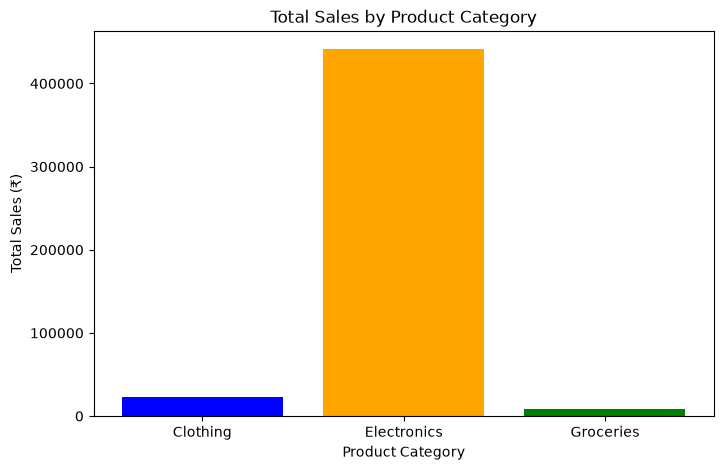

In [9]:
#  task 2 
import matplotlib.pyplot as plt

category_sales = df.groupby('category')['sales'].sum()

plt.figure(figsize=(8, 5))
plt.bar(category_sales.index, category_sales.values,
        color=['blue', 'orange', 'green'])

plt.title('Total Sales by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Sales (₹)')

plt.show()

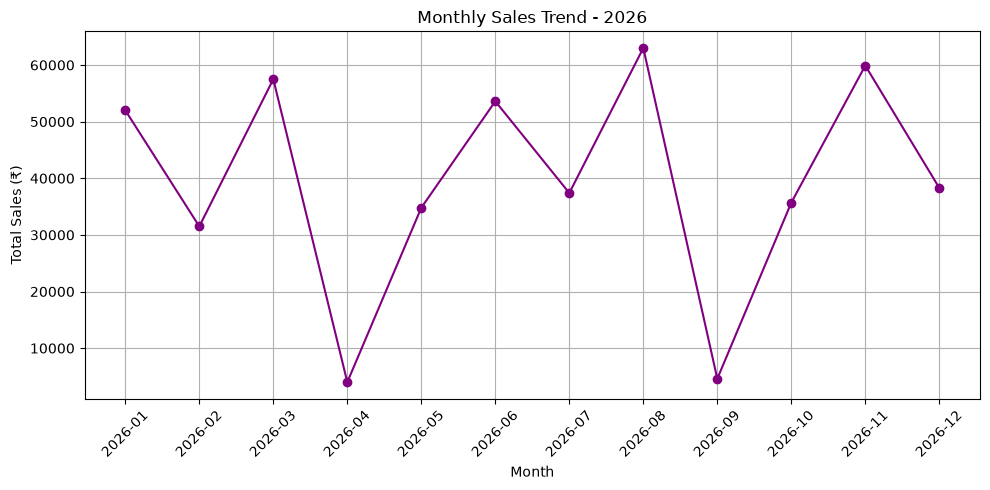

In [10]:
#  task 3 
monthly_sales = df.groupby(
    df['date'].dt.to_period('M')
)['sales'].sum()

plt.figure(figsize=(10, 5))
plt.plot(monthly_sales.index.astype(str),
         monthly_sales.values,
         marker='o',
         color='purple')

plt.title('Monthly Sales Trend - 2026')
plt.xlabel('Month')
plt.ylabel('Total Sales (₹)')
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

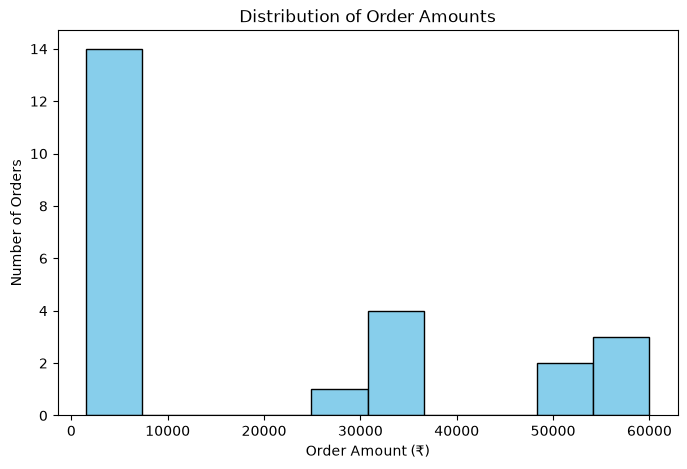

In [11]:
#  task 4 
plt.figure(figsize=(8, 5))

plt.hist(df['sales'], bins=10,
         color='skyblue', edgecolor='black')

plt.title('Distribution of Order Amounts')
plt.xlabel('Order Amount (₹)')
plt.ylabel('Number of Orders')

plt.show()

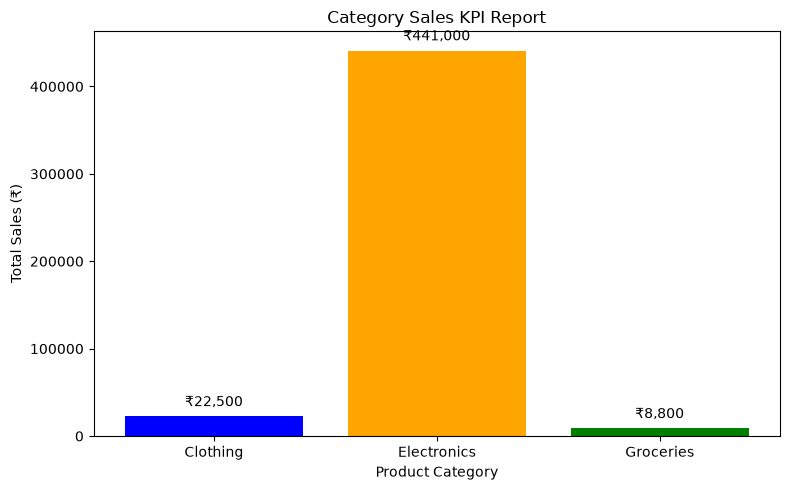

In [12]:
#  task 5 
category_sales = df.groupby('category')['sales'].sum()

plt.figure(figsize=(8, 5))

bars = plt.bar(
    category_sales.index,
    category_sales.values,
    color=['blue', 'orange', 'green']
)

plt.title('Category Sales KPI Report')
plt.xlabel('Product Category')
plt.ylabel('Total Sales (₹)')

# Add sales values above each bar
for bar in bars:
    height = bar.get_height()

    plt.annotate(
        f'₹{height:,.0f}',
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 5),
        textcoords='offset points',
        ha='center',
        va='bottom'
    )

plt.tight_layout()

plt.savefig(
    'category_sales_kpi.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()